In [8]:
import sys
import sklearn

print(sys.executable)
print("scikit-learn:", sklearn.__version__)

/Users/mrkarim/Documents/Codex/2026-09-28/to-x20/portfolio/ai-engineering-study-log/projects/fastapi_02_ml_prediction_api/.venv/bin/python
scikit-learn: 1.9.1


Inspect the flower data

Each row is one flower. The four columns are its measurements. First, I’ll check the table’s size, look at a few rows, and count missing measurements.

In [9]:
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris()
measurements = pd.DataFrame(iris.data, columns=iris.feature_names)

print("Rows and columns:", measurements.shape)
print("Missing measurements:", measurements.isna().sum().sum())
measurements.head()

Rows and columns: (150, 4)
Missing measurements: 0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [10]:
from sklearn.model_selection import train_test_split

labels = iris.target
print("Species:", iris.target_names)

train_features, test_features, train_labels, test_labels = train_test_split(
    measurements,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels,
)

print("Training flowers:", len(train_features))
print("Test flowers:", len(test_features))

Species: ['setosa' 'versicolor' 'virginica']
Training flowers: 120
Test flowers: 30


In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier

baseline = DummyClassifier(strategy="most_frequent")
tree = DecisionTreeClassifier(max_depth=3, random_state=42)

baseline.fit(train_features, train_labels)
tree.fit(train_features, train_labels)

baseline_correct = (baseline.predict(test_features) == test_labels).sum()
tree_correct = (tree.predict(test_features) == test_labels).sum()

print(f"Baseline: {baseline_correct}/{len(test_labels)} correct")
print(f"Decision tree: {tree_correct}/{len(test_labels)} correct")

Baseline: 10/30 correct
Decision tree: 29/30 correct


In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

scaled_measurements = StandardScaler().fit_transform(measurements)

kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
clusters = kmeans.fit_predict(scaled_measurements)

print("Flowers per cluster:")
print(pd.Series(clusters).value_counts().sort_index())

Flowers per cluster:
0    53
1    50
2    47
Name: count, dtype: int64


In [13]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_coordinates = pca.fit_transform(scaled_measurements)

print("Before PCA:", scaled_measurements.shape)
print("After PCA:", pca_coordinates.shape)
print("Variation per component:", pca.explained_variance_ratio_)
print(
    f"Total variation retained: "
    f"{pca.explained_variance_ratio_.sum():.1%}"
)

Before PCA: (150, 4)
After PCA: (150, 2)
Variation per component: [0.72962445 0.22850762]
Total variation retained: 95.8%


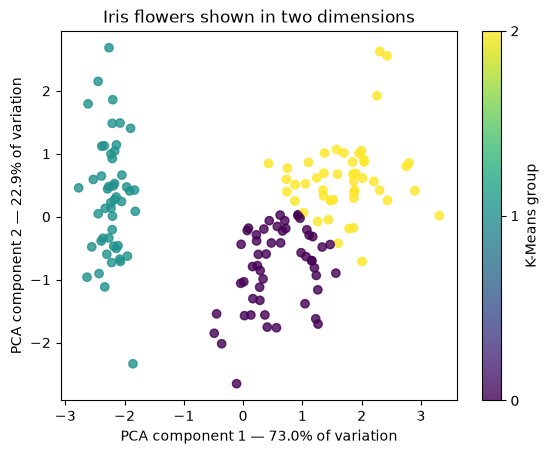

In [14]:
import matplotlib.pyplot as plt

dots = plt.scatter(
    pca_coordinates[:, 0],
    pca_coordinates[:, 1],
    c=clusters,
    cmap="viridis",
    alpha=0.8,
)

plt.xlabel("PCA component 1 — 73.0% of variation")
plt.ylabel("PCA component 2 — 22.9% of variation")
plt.title("Iris flowers shown in two dimensions")
plt.colorbar(dots, ticks=[0, 1, 2], label="K-Means group")
plt.show()

## What I learned

I explored 150 flowers, each with four measurements.

The decision tree learned to predict species. It got 29/30 correct,
compared with 10/30 for the baseline.

K-Means grouped flowers with similar measurements without using
their species names. The groups contained 53, 50 and 47 flowers.

PCA combined the four measurements into two summary numbers
per flower so I could draw them on a graph.

On the graph, PCA determines the positions and K-Means determines
the colors.